In [ ]:
# !pip install pandas
import pandas as pd
import re
import pickle
from datetime import datetime
from bertopic import BERTopic
import matplotlib.pyplot as p
import networkx as nx
import requests
import numpy as np
# import networks_layouts
from matplotlib import colors
import pickle

import ast
def convert_str_to_list(x):
    try:
        return ast.literal_eval(x, '|')
    except:
        return None
def read_pickle(file_name):
    '''Function to read pickles faster'''
    pickle_in = open(file_name, 'rb')
    variable = pickle.load(pickle_in)
    return variable

def write_pickle(variable, file_name):
    '''Function to write pickles faster'''
    pickle_out = open(file_name, 'wb')
    pickle.dump(variable, pickle_out)

#Move all files of one folder to another one:
from os import listdir
from os.path import isfile, join
import os
import shutil

/Users/anajaramillo/Dropbox/Post-docs/1. Post-doc Mammoth/18. Peace research/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1110 15:45:02.223000 18301 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


64

# From here starts the text analyses:

In [1]:
#!pip install nltk
from sentence_transformers import SentenceTransformer
import sys
sys.path.insert(1, '/Users/anajaramillo/.local/lib/python3.13/site-packages')

from numpy.typing import NDArray
import torch
from torch import tensor

import nltk
nltk.download("punkt")
nltk.download("punkt_tab")

def split_into_sentences(text):
  """Splits a text into sentences using NLTK’s sentence tokenizer."""
  from nltk.tokenize import sent_tokenize
  return sent_tokenize(text)

/Users/anajaramillo/Dropbox/Post-docs/1. Post-doc Mammoth/18. Peace research/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1110 16:18:21.259000 19372 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
[nltk_data] Downloading package punkt to
[nltk_data]     /Users/anajaramillo/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/anajaramillo/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
%%time
from scipy.spatial import distance
from sentence_transformers import SentenceTransformer, util

model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt
vectorizer = CountVectorizer()

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11678.88it/s]


CPU times: user 230 ms, sys: 216 ms, total: 446 ms
Wall time: 1.33 s


In [33]:
#Abstract preprocessing
nltk.download('stopwords')
from nltk.corpus import stopwords
from collections import Counter
import re
stop_words = stopwords.words('english')
stopwords_dict = Counter(stop_words)

def pre_process_text(text):
    dlist = re.sub(r'https?:\/\/.*[\r\n]*', ' ', str(text), flags=re.MULTILINE) #removes links
    dlist = re.sub(r'[^A-Za-z \']', ' ', str(dlist)).lower()   #lowercase
    dlist = re.sub(r'[,"!?:@\$%_]+', ' ', str(dlist), flags=re.MULTILINE)
    dlist = re.sub(r'\.+', ' ', str(dlist), flags=re.MULTILINE) #remove multiple dots
    dlist = re.sub(r'\?+', ' ', str(dlist), flags=re.MULTILINE) #remove multiple ?
    dlist = re.sub(r'\!+', ' ', str(dlist), flags=re.MULTILINE) #remove multiple !
    dlist = re.sub(r"'", '', str(dlist), flags=re.MULTILINE)
    dlist = re.sub(r"\s+"," ", str(dlist), flags=re.MULTILINE) #remove multiple spaces
    dlist = re.sub(r'[0-9]+', '', str(dlist)) #remove numbers from the string
    dlist = ' '.join([word for word in dlist.split() if word not in stopwords_dict])
    return dlist.upper()


[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/anajaramillo/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
List_translated_abstract = read_pickle('List_translated_abstracts/List_translated_abstract.pkl')
Filtered_DataFrame_out = read_pickle('Filtered_DataFrame_out.pkl')

In [18]:
%%time
english_abstract = []
for i in Filtered_DataFrame_out.index:
    id_paper = Filtered_DataFrame_out.id[i]
    try:
        english_abstract += [List_translated_abstract[id_paper]]
    except:
        if Filtered_DataFrame_out.detected_language[i] == 'en':
            english_abstract += [Filtered_DataFrame_out.abstract[i]]
        else:
            english_abstract += ['']
        pass
            
Filtered_DataFrame_out['english_abstract'] = english_abstract       

CPU times: user 1.22 s, sys: 6.9 ms, total: 1.22 s
Wall time: 1.22 s


In [19]:
Filtered_DataFrame_out_filt = Filtered_DataFrame_out[Filtered_DataFrame_out.english_abstract!='']

In [81]:
Concepts_of_peace = ["negative peace", "positive peace", "restorative justice",
                     "state building", "reconciliation", "security", "community"]


In [27]:
Filtered_DataFrame_out_filt['primary_location.source.id'] = [i.replace('https://openalex.org/','') for i in Filtered_DataFrame_out_filt['primary_location.source.id']]

In [23]:
Filtered_DataFrame_out_filt = Filtered_DataFrame_out_filt[~Filtered_DataFrame_out_filt['primary_location.source.id'].isna()]


In [28]:
def Concepts_search_and_generate_DF_over_all(Concepts, Filtered_DataFrame_out_filt)
    Dict_concepts_keys = {}
    Keys_list = ['english_abstract', 'primary_topic.display_name']
    Dict_concepts_keys = {}
    
    DF_with_key = {Filtered_DataFrame_out_filt.id[i]:';'.join([str(Filtered_DataFrame_out_filt[k][i]).upper() for k in Keys_list]) for i in Filtered_DataFrame_out_filt.index }
    
    for concept in Concepts:
        Dict_concepts_keys[concept] = [i for i,v in DF_with_key.items() if concept.upper() in v]
    
    return pd.DataFrame({'concept':[i for i in Dict_concepts_keys.keys()],
                  'Number of papers': [str(len(v))+' ('+str(np.round(len(v)/Filtered_DataFrame_out_filt.shape[0],3))+')' for i,v in Dict_concepts_keys.items()]})


,concept,Number of papers
0,negative peace,164 (0.005)
1,positive peace,349 (0.01)
2,restorative justice,327 (0.01)
3,state-building,229 (0.007)
4,reconciliation,2270 (0.066)
5,security,10840 (0.317)
6,community,5820 (0.17)


In [74]:
Dict_concepts_keys = {}
for key in ['english_abstract', 'primary_topic.display_name']:
    Dict_concepts_keys[key] = {}

    DF_with_key = Filtered_DataFrame_out_filt[~Filtered_DataFrame_out_filt[key].isnull()]
    
    for concept in Concepts_of_peace:
        Dict_concepts_keys[key][concept] = DF_with_key[DF_with_key[key].apply(lambda x: concept.upper() in x.upper())].shape[0]
    
pd.DataFrame(Dict_concepts_keys)

,english_abstract,primary_topic.display_name
negative peace,178,0
positive peace,386,0
restorative justice,352,0
state-building,245,0
reconciliation,2493,0
security,9057,4989
community,6300,47


In [56]:
Dict_papers_per_region = {}

for i in Filtered_DataFrame_out_filt.index:
    paper = Filtered_DataFrame_out_filt.id[i]
    journal = Filtered_DataFrame_out_filt['primary_location.source.id'][i]
    for region in Dict_countries_regions.keys():
        for country in Dict_countries_regions[region]:
            if journal in Dict_journals_per_country[country]:
                try:
                    Dict_papers_per_region[region] += [paper]
                except:
                    Dict_papers_per_region[region] = [paper]
                    pass
                    
Dict_number_papers_per_region = {}

for k in Dict_papers_per_region.keys():
    Dict_number_papers_per_region[k] = int(len(Dict_papers_per_region[k]))                       

In [202]:
def Concepts_search_and_generate_DF_with_regions(Concepts, Filtered_DataFrame_out_filt, Dict_countries_regions,Dict_number_papers_per_region, separated=False):
    Dict_concepts_keys = {}
    Keys_list = ['english_abstract', 'primary_topic.display_name']
    Dict_concepts_keys = {}
    
    DF_with_key = {Filtered_DataFrame_out_filt.id[i]:';'.join([str(Filtered_DataFrame_out_filt[k][i]).upper() for k in Keys_list]) for i in Filtered_DataFrame_out_filt.index }
    
    for concept in Concepts:
        list_concepts = concept.split(' ')
        if len(list_concepts) == 1:
            Dict_concepts_keys[concept] = [i for i,v in DF_with_key.items() if concept.upper() in v]
        else:
            if separated == True:
                Dict_concepts_keys[concept] = [i for i,v in DF_with_key.items() if (list_concepts[0].upper() in v) and (list_concepts[1].upper() in v)]
            else:
                Dict_concepts_keys[concept] = [i for i,v in DF_with_key.items() if (concept.upper() in v) or (''.join(list_concepts).upper() in v) or ('-'.join(list_concepts).upper() in v)]
                
    
    Dict_concept_region_papers = {}

    for concept in Concepts:
        Dict_concept_region_papers[concept] = {}
        for paper in Dict_concepts_keys[concept]:
            journal = Filtered_DataFrame_out_filt[Filtered_DataFrame_out_filt.id==paper]['primary_location.source.id'].iloc[0]
            for region in Dict_countries_regions.keys():
                for country in Dict_countries_regions[region]:
                    if journal in Dict_journals_per_country[country]:
                        try:
                            Dict_concept_region_papers[concept][region] += [paper]
                        except:
                            Dict_concept_region_papers[concept][region] = [paper]
                            pass
    
    Dict_concept_region_number_of_papers = {}
    
    for k in Dict_concept_region_papers.keys():
        Dict_concept_region_number_of_papers[k] = {}
        for v in Dict_concept_region_papers[k].keys():
            n_papers_c_r = len(Dict_concept_region_papers[k][v])
            p_papers_r =  Dict_number_papers_per_region[v]
            Dict_concept_region_number_of_papers[k][v] = str(n_papers_c_r)+ ' (' + str(np.round(n_papers_c_r/p_papers_r,2)) + ')'
    
    return pd.DataFrame(Dict_concept_region_number_of_papers).sort_index()

In [95]:
%%time
DF_original = Concepts_search_and_generate_DF_with_regions(Concepts_of_peace, Filtered_DataFrame_out_filt, Dict_countries_regions,Dict_number_papers_per_region)

CPU times: user 44.5 s, sys: 1.3 s, total: 45.8 s
Wall time: 46 s


In [738]:
Concepts_state_centtric = ["conflict resolution", "ceasefire", "political order", "state security"]

Concepts_search_and_generate_DF_with_regions(Concepts_state_centtric, Filtered_DataFrame_out_filt, Dict_countries_regions,Dict_number_papers_per_region)


,conflict resolution,ceasefire,political order,state security
Australia and New Zealand (UN M49),8 (0.07),3 (0.02),1 (0.01),NaN
Central Asia (UN M49),1 (0.05),NaN,NaN,NaN
Eastern Asia (UN M49),9 (0.02),3 (0.01),NaN,1 (0.0)
Eastern Europe (UN M49),108 (0.08),13 (0.01),11 (0.01),3 (0.0)
Latin America and the Caribbean (UN M49),515 (0.16),14 (0.0),3 (0.0),3 (0.0)
Micronesia (UN M49),4 (0.27),NaN,NaN,NaN
Northern Africa (UN M49),2 (0.01),1 (0.01),NaN,1 (0.01)
Northern America (UN M49),201 (0.09),25 (0.01),12 (0.01),8 (0.0)
Northern Europe (UN M49),160 (0.07),35 (0.02),25 (0.01),9 (0.0)
Polynesia (UN M49),3 (0.3),NaN,NaN,NaN


In [ ]:
Concepts_search_and_generate_DF_with_regions(Concepts_of_peace, Filtered_DataFrame_out_filt, Dict_countries_regions,Dict_number_papers_per_region)

,negative peace,positive peace,restorative justice,state building,reconciliation,security,community
Australia and New Zealand (UN M49),1 (0.01),1 (0.01),1 (0.01),2 (0.02),6 (0.05),38 (0.31),28 (0.23)
Central Asia (UN M49),NaN,NaN,1 (0.05),1 (0.05),1 (0.05),9 (0.41),2 (0.09)
Eastern Asia (UN M49),1 (0.0),2 (0.0),NaN,4 (0.01),17 (0.03),64 (0.11),26 (0.04)
Eastern Europe (UN M49),6 (0.0),15 (0.01),4 (0.0),20 (0.01),77 (0.05),616 (0.44),188 (0.13)
Latin America and the Caribbean (UN M49),15 (0.0),30 (0.01),64 (0.02),21 (0.01),241 (0.07),476 (0.14),456 (0.14)
Micronesia (UN M49),NaN,NaN,NaN,NaN,NaN,10 (0.67),4 (0.27)
Northern Africa (UN M49),NaN,1 (0.01),NaN,NaN,5 (0.04),31 (0.22),19 (0.14)
Northern America (UN M49),9 (0.0),17 (0.01),13 (0.01),28 (0.01),136 (0.06),704 (0.32),373 (0.17)
Northern Europe (UN M49),11 (0.0),27 (0.01),12 (0.01),43 (0.02),149 (0.07),887 (0.4),337 (0.15)
Polynesia (UN M49),NaN,NaN,NaN,NaN,NaN,1 (0.1),2 (0.2)


In [101]:
Concepts_community_centered = ["restorative justice", "grassroots peace", "community initiatives", "reconciliation"]

Concepts_search_and_generate_DF_with_regions(Concepts_community_centered, Filtered_DataFrame_out_filt, Dict_countries_regions,Dict_number_papers_per_region)

,restorative justice,grassroots peace,community initiatives,reconciliation
Australia and New Zealand (UN M49),1 (0.01),1 (0.01),NaN,6 (0.05)
Central Asia (UN M49),1 (0.05),NaN,NaN,1 (0.05)
Eastern Asia (UN M49),NaN,1 (0.0),NaN,17 (0.03)
Eastern Europe (UN M49),4 (0.0),NaN,1 (0.0),77 (0.05)
Latin America and the Caribbean (UN M49),64 (0.02),NaN,4 (0.0),241 (0.07)
Northern Africa (UN M49),NaN,NaN,NaN,5 (0.04)
Northern America (UN M49),13 (0.01),2 (0.0),NaN,136 (0.06)
Northern Europe (UN M49),12 (0.01),3 (0.0),NaN,149 (0.07)
South-eastern Asia (UN M49),30 (0.01),NaN,3 (0.0),166 (0.08)
Southern Asia (UN M49),5 (0.0),1 (0.0),NaN,72 (0.06)


In [115]:
Concepts_alternative_peace = ["feminist peace", "indigen sovereignty", "decolon theory",  "plural knowledge"]

Concepts_search_and_generate_DF_with_regions(Concepts_alternative_peace, Filtered_DataFrame_out_filt, Dict_countries_regions,Dict_number_papers_per_region, separated=True)


,feminis peace,indigen sovereignty,decolon theory,plural knowledge
Australia and New Zealand (UN M49),5 (0.04),NaN,NaN,1 (0.01)
Eastern Asia (UN M49),2 (0.0),NaN,NaN,NaN
Eastern Europe (UN M49),7 (0.0),1 (0.0),NaN,1 (0.0)
Latin America and the Caribbean (UN M49),30 (0.01),2 (0.0),2 (0.0),6 (0.0)
Northern Africa (UN M49),NaN,NaN,NaN,1 (0.01)
Northern America (UN M49),31 (0.01),5 (0.0),4 (0.0),8 (0.0)
Northern Europe (UN M49),82 (0.04),4 (0.0),6 (0.0),8 (0.0)
South-eastern Asia (UN M49),12 (0.01),1 (0.0),NaN,5 (0.0)
Southern Asia (UN M49),11 (0.01),NaN,3 (0.0),1 (0.0)
Southern Europe (UN M49),29 (0.02),2 (0.0),3 (0.0),7 (0.01)


# 2. Search the terms based on the dictionary:


In [841]:
Dictionary_of_terms = pd.read_table('Dictionary_of_terms_dominant_paradigms.csv',delimiter=';',header=0)

from sentence_transformers import SentenceTransformer

# Loading the model 
model = SentenceTransformer('all-MiniLM-L6-v2')

def Compare_Text_with_terms(text_1, Dictionary_of_terms):

    Probability_string_term = {Term.upper():[] for Term in Dictionary_of_terms.Term}
    Probability_term = {Term.upper():[] for Term in Dictionary_of_terms.Term}
    Appearance_term = {Term.upper():[] for Term in Dictionary_of_terms.Term}
    
    text = pre_process_text(text_1)
    sentences = split_into_sentences(text_1)

    # Generating vector embeddings from the list
    embeddings = model.encode(sentences, show_progress_bar=False)
    
    for index in Dictionary_of_terms.index:
        term,user_query = Dictionary_of_terms['Term'][index].upper(),Dictionary_of_terms['Definition'][index].upper()
        query_embedding = model.encode([pre_process_text(user_query)])[0]
        List_similarities = []
        for sentence in embeddings:
            similarity = np.dot(
              np.array(query_embedding), 
              np.array(sentence)
            ) / (
              np.linalg.norm(np.array(query_embedding)) * 
              np.linalg.norm(sentence)
            )
            List_similarities  += [np.round(similarity,2)]

        Probability_term[term] = List_similarities
            
        if 0.5 in [0.5 for i in List_similarities if i >0.5]:
            Probability_string_term[term] = '>0.5'
    
        elif 0.4 in [0.4 for i in List_similarities if i <=0.5 and i >0.4]:
            Probability_string_term[term] = '>0.4'
        else:
            Probability_string_term[term] = '<=0.4'

        if ' ' in term:
            list_concepts = term.split(' ')
        elif '-' in term:
            list_concepts = term.split('-')
            
        if len(list_concepts) == 1:
            if term.upper() in text.upper():
                Appearance_term[term] = 'Yes'
            else:
                Appearance_term[term] = 'No'    
        else:
            if term in text_1:
                Appearance_term[term] = 'Yes'
            elif ''.join(list_concepts).upper() in text_1:
                Appearance_term[term] = 'Yes'
            elif '-'.join(list_concepts).upper() in text_1:
                Appearance_term[term] = 'Yes'
            elif ' '.join(list_concepts).upper() in text_1:
                Appearance_term[term] = 'Yes'
            else:
                appears = []
                for concept in list_concepts:
                    if concept in text_1:
                        appears +=[True]
                    else:
                        appears +=[False]
                if False not in appears:  
                    Appearance_term[term] = 'Yes'
                else:
                    Appearance_term[term] = 'No'

    return Probability_term, Probability_string_term, Appearance_term
    
        

Loading weights: 100%|██████████████████████| 103/103 [00:00<00:00, 7220.32it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
%%time
Probability_term, Probability_string_term, Appearance_term = {}, {}, {}
for i, text in enumerate(List_translated_abstract):
    Probability_term[i], Probability_string_term[i], Appearance_term[i] = Compare_Text_with_terms(text, Dictionary_of_terms)
DF_Terms_probabilities = pd.DataFrame(Probability_string_term).T


In [130]:
Proportions_for_plots = {}
for k in DF_Terms_probabilities.keys():
    Proportions_for_plots[k] = dict(DF_Terms_probabilities[k].value_counts()/DF_Terms_probabilities.shape[0])
    

plt.rcParams['mathtext.fontset'] = 'dejavusans'
width = 0.6
font_size_out = 10
nrows = 1
ncols = 1
# letters = [['  '+alphabet_list[i*ncols+j] for j in range(ncols)] for i in range(nrows)]
fig, ax = plt.subplots(ncols=ncols, nrows=nrows,figsize=(10*ncols,5*nrows), sharex= False, sharey= False,
                       gridspec_kw={'width_ratios': [1]})

df_com_div = Proportions_for_plots

# ax[row_plt][col_plt].text(0.5, 1.05,, horizontalalignment='center',
# verticalalignment='bottom',weight="bold", fontsize=font_size_out+8, transform=ax[row_plt][col_plt].transAxes)                

labels = list(Proportions_for_plots[k].keys())


pd.DataFrame(Proportions_for_plots).T.plot(kind='bar', stacked=True, ax = ax, color = ['#3B8EA5', '#F49E4C', '#AB3428'])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.yaxis.set_ticks_position('left')
ax.xaxis.set_ticks_position('bottom')
ax.xaxis.set_tick_params(width=1,  pad=5)
ax.yaxis.set_tick_params(width=1, pad=5)

ax.tick_params('x', size=5, colors="black", labelsize=font_size_out+1)
ax.tick_params('y', size=5, colors="black", labelsize=font_size_out+1)

for axis in ['top','bottom','left','right']:
    ax.spines[axis].set_linewidth(1)
    ax.spines[axis].set_color("black")
    ax.spines[axis].set_zorder(0)


# ax.set_ylim(0,2200)
for bar,seg in enumerate(Proportions_for_plots.keys()):
    Numbers = list(Proportions_for_plots[seg].keys())
    ax.text(bar,Proportions_for_plots[seg]['<=0.4']/2,str(np.round(Proportions_for_plots[seg]['<=0.4'],2)), color='white', 
            size=(font_size_out), 
            horizontalalignment='center', verticalalignment='center', rotation=90)
    cumulative_y = 0
    for i in Numbers[1:]:
        cumulative_y += Proportions_for_plots[seg][Numbers[Numbers.index(i)-1]]
        ax.text(+bar,Proportions_for_plots[seg][i]/2+cumulative_y,str(np.round(Proportions_for_plots[seg][i],2)), color='white', 
                size=(font_size_out)*Proportions_for_plots[seg][i]*3+2, 
                horizontalalignment='center', verticalalignment='center', rotation=90)

# for p,color in zip(ax[row_plt][col_plt].patches,colors):
#     p.set_facecolor(color)
#     p.set_alpha(0.8)

# ax[row_plt][col_plt].set_xticklabels(Achronym.values())

            
# ax[row_plt][col_plt].set_ylabel(Name_ylabels[diver_metric], fontsize=font_size_out+6,
#                                         labelpad=30, va='center', ha='center')
    
        
fig.tight_layout(h_pad=1.5, w_pad=2)
# plt.savefig('Diversities_CS_'+str(Year)+'.pdf')        
plt.show()

,Term,Definition
0,Security,"Broadly, a condition in which people or states..."
1,State-building,The process of constructing or strengthening s...
2,Conflict resolution,Methods and processes aimed at ending conflict...
3,Ceasefire,A temporary stoppage of hostilities agreed by ...
4,Political order,The institutional and legal framework (constit...
5,Rule of law,Principle that all individuals and institution...
6,Peacekeeping,Deployment of international forces (often UN) ...
7,Stabilization,Actions (often by international actors) to sta...
8,Development,"In peace/conflict, often refers to economic an..."
9,Governance,The processes and institutions through which a...


In [175]:
def Semantic_search(Filtered_DataFrame_out_filt, Dictionary_of_terms):
    Dict_concepts_keys = {}
    Keys_list = ['english_abstract', 'primary_topic.display_name']
    Dict_concepts_keys = {}
    
    DF_with_key = {Filtered_DataFrame_out_filt.id[i]:';'.join([str(Filtered_DataFrame_out_filt[k][i]).upper() for k in Keys_list]) for i in Filtered_DataFrame_out_filt.index }

    Probability_term, Probability_string_term, Appearance_term = {}, {}, {}
    for i,k in enumerate(DF_with_key.keys()):
        if i%1000==0:
            print(i)
        text = DF_with_key[k]
        Probability_term[k], Probability_string_term[k], Appearance_term[k] = Compare_Text_with_terms(text, Dictionary_of_terms)
    
    for term in Dictionary_of_terms.Term:
       Filtered_DataFrame_out_filt['Probability_term_'+term] = [Probability_term[k][term.upper()] for k in Filtered_DataFrame_out_filt.id]
       Filtered_DataFrame_out_filt['Probability_string_term_'+term] = [Probability_string_term[k][term.upper()] for k in Filtered_DataFrame_out_filt.id]
       Filtered_DataFrame_out_filt['Appearance_term_'+term] = [Appearance_term[k][term.upper()] for k in Filtered_DataFrame_out_filt.id]

    
    return Filtered_DataFrame_out_filt
    
    

In [754]:
def make_table_based_on_semantic_similarity(Filtered_DataFrame_out_filt, Dictionary_of_terms,semantic=True, prob_passing = 0.6):
    Dict_concept_region_papers = {}
    
    for concept in Dictionary_of_terms.Term:
        # if semantic:
        #     Journals_papers_concept = list(Filtered_DataFrame_out_filt[Filtered_DataFrame_out_filt['Probability_string_term_'+concept]=='>0.4']['primary_location.source.id'])
        # else:
        #     Journals_papers_concept = list(Filtered_DataFrame_out_filt[Filtered_DataFrame_out_filt['Appearance_term_'+concept]=='Yes']['primary_location.source.id'])

        Journals_papers_concept = list(Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+concept].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+concept]=='Yes')]['primary_location.source.id'])

        Dict_concept_region_papers[concept] = {}
        for journal in Journals_papers_concept:
            for region in Dict_countries_regions.keys():
                for country in Dict_countries_regions[region]:
                    if journal in Dict_journals_per_country[country]:
                        try:
                            Dict_concept_region_papers[concept][region] += [paper]
                        except:
                            Dict_concept_region_papers[concept][region] = [paper]
                            pass
    
    Dict_concept_region_number_of_papers = {}
    
    for k in Dict_concept_region_papers.keys():
        Dict_concept_region_number_of_papers[k] = {}
        for v in Dict_concept_region_papers[k].keys():
            n_papers_c_r = len(Dict_concept_region_papers[k][v])
            p_papers_r =  Dict_number_papers_per_region[v+' (UN M49)']
            Dict_concept_region_number_of_papers[k][v] = str(n_papers_c_r)+ ' (' + str(np.round(n_papers_c_r/p_papers_r,2)) + ')'
    
    return pd.DataFrame(Dict_concept_region_number_of_papers).sort_index()
    

In [ ]:
%%time
file = 'Dictionary_of_terms_realist_dominant_paradigms.csv'
Dictionary_of_terms = pd.read_table(file,delimiter=';',header=0)
make_table_based_on_semantic_similarity(Filtered_DataFrame_out_filt, Dictionary_of_terms,prob_passing=0.65)

CPU times: user 2.52 s, sys: 13.9 ms, total: 2.54 s
Wall time: 2.54 s


,Security,Political order,State-building,Conflict resolution,Ceasefire
Australia and New Zealand,38 (0.31),1 (0.01),3 (0.02),8 (0.07),3 (0.02)
Central Asia,9 (0.41),NaN,1 (0.05),1 (0.05),NaN
Eastern Asia,64 (0.11),NaN,4 (0.01),9 (0.02),3 (0.01)
Eastern Europe,617 (0.44),11 (0.01),20 (0.01),109 (0.08),13 (0.01)
Latin America and the Caribbean,480 (0.15),3 (0.0),21 (0.01),523 (0.16),14 (0.0)
Micronesia,10 (0.67),NaN,NaN,4 (0.27),NaN
Northern Africa,31 (0.22),NaN,NaN,2 (0.01),1 (0.01)
Northern America,705 (0.32),13 (0.01),28 (0.01),203 (0.09),25 (0.01)
Northern Europe,889 (0.4),26 (0.01),43 (0.02),164 (0.07),35 (0.02)
Polynesia,1 (0.1),NaN,NaN,3 (0.3),NaN


In [ ]:
# file = 'Dictionary_of_terms_liberal_dominant_paradigms.csv'
# Dictionary_of_terms_liberal = pd.read_table(file,delimiter=';',header=0)
make_table_based_on_semantic_similarity(Filtered_DataFrame_out_filt, Dictionary_of_terms_liberal,prob_passing=0.65)

,Democratic peace,Human rights,Peacebuilding,Peacemaking,Reconciliation,Development
Australia and New Zealand,1 (0.01),17 (0.14),12 (0.1),2 (0.02),6 (0.05),43 (0.35)
Central Asia,NaN,NaN,1 (0.05),NaN,1 (0.05),12 (0.55)
Eastern Asia,1 (0.0),15 (0.03),26 (0.04),3 (0.01),17 (0.03),110 (0.19)
Eastern Europe,7 (0.0),143 (0.1),92 (0.07),32 (0.02),77 (0.05),478 (0.34)
Latin America and the Caribbean,4 (0.0),419 (0.13),232 (0.07),10 (0.0),241 (0.07),772 (0.23)
Micronesia,NaN,3 (0.2),5 (0.33),NaN,NaN,8 (0.53)
Northern Africa,2 (0.01),8 (0.06),5 (0.04),1 (0.01),5 (0.04),27 (0.2)
Northern America,26 (0.01),234 (0.11),286 (0.13),46 (0.02),136 (0.06),651 (0.3)
Northern Europe,23 (0.01),260 (0.12),494 (0.22),40 (0.02),149 (0.07),592 (0.26)
Polynesia,NaN,NaN,NaN,NaN,NaN,4 (0.4)


In [ ]:
%%time
file = 'Dictionary_of_terms_institutional_dominant_paradigms.csv'
# Dictionary_of_terms_institutional = pd.read_table(file,delimiter=';',header=0)
concept = 'Rule of law'
# Filtered_DataFrame_out_filt = Semantic_search(Filtered_DataFrame_out_filt, Dictionary_of_terms_institutional[Dictionary_of_terms_institutional.Term == concept])

# write_pickle(Filtered_DataFrame_out_filt, 'Filtered_DataFrame_out_filt.pkl')
make_table_based_on_semantic_similarity(Filtered_DataFrame_out_filt, Dictionary_of_terms_institutional,prob_passing=0.65)

CPU times: user 3.47 s, sys: 735 ms, total: 4.2 s
Wall time: 6.14 s


In [773]:
%%time
# file = 'Dictionary_of_terms_local_turn_critical_paradigms.csv'
# Dictionary_of_terms_local_turn = pd.read_table(file,delimiter=';',header=0)
# Filtered_DataFrame_out_filt = Semantic_search(Filtered_DataFrame_out_filt, Dictionary_of_terms_local_turn)
# write_pickle(Filtered_DataFrame_out_filt, 'Filtered_DataFrame_out_filt.pkl')
make_table_based_on_semantic_similarity(Filtered_DataFrame_out_filt, Dictionary_of_terms_local_turn,prob_passing=0.65)
# concept = 'Local turn'
# Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+concept].apply(lambda x: x[0]>0.65)) | (Filtered_DataFrame_out_filt['Appearance_term_'+concept]=='Yes')].iloc[0]['english_abstract']

CPU times: user 658 ms, sys: 4.5 ms, total: 662 ms
Wall time: 662 ms


,Liberal peace,Local turn,Everyday peace,Hybridity,Participation,Community resilience,Grassroots peace,Community-led initiatives
Australia and New Zealand,NaN,NaN,NaN,NaN,8 (0.07),2 (0.02),1 (0.01),NaN
Central Asia,1 (0.05),NaN,NaN,NaN,1 (0.05),NaN,NaN,NaN
Eastern Asia,1 (0.0),2 (0.0),2 (0.0),3 (0.01),11 (0.02),1 (0.0),1 (0.0),1 (0.0)
Eastern Europe,3 (0.0),4 (0.0),1 (0.0),2 (0.0),106 (0.08),NaN,NaN,2 (0.0)
Latin America and the Caribbean,21 (0.01),15 (0.0),1 (0.0),3 (0.0),330 (0.1),3 (0.0),NaN,7 (0.0)
Micronesia,NaN,1 (0.07),NaN,1 (0.07),2 (0.13),NaN,NaN,1 (0.07)
Northern Africa,NaN,NaN,NaN,NaN,3 (0.02),NaN,NaN,NaN
Northern America,21 (0.01),22 (0.01),7 (0.0),16 (0.01),122 (0.06),1 (0.0),2 (0.0),15 (0.01)
Northern Europe,56 (0.03),48 (0.02),21 (0.01),35 (0.02),160 (0.07),4 (0.0),3 (0.0),26 (0.01)
Polynesia,NaN,NaN,NaN,NaN,1 (0.1),NaN,NaN,NaN


In [782]:
%%time
# file = 'Dictionary_of_terms_feminist_security_studies_critical_paradigms.csv'
# Dictionary_of_terms_feminist_security_studies = pd.read_table(file,delimiter=';',header=0)
# Filtered_DataFrame_out_filt = Semantic_search(Filtered_DataFrame_out_filt, Dictionary_of_terms_feminist_security_studies)
write_pickle(Filtered_DataFrame_out_filt, 'Filtered_DataFrame_out_filt.pkl')
make_table_based_on_semantic_similarity(Filtered_DataFrame_out_filt, Dictionary_of_terms_feminist_security_studies,prob_passing=0.65)

CPU times: user 3.56 s, sys: 252 ms, total: 3.82 s
Wall time: 4.23 s


,Feminist Peace,Care,Intersectionality,Continuum of violence
Australia and New Zealand,4 (0.03),18 (0.15),4 (0.03),1 (0.01)
Central Asia,NaN,1 (0.05),NaN,NaN
Eastern Asia,2 (0.0),60 (0.1),2 (0.0),1 (0.0)
Eastern Europe,9 (0.01),58 (0.04),7 (0.0),4 (0.0)
Latin America and the Caribbean,30 (0.01),166 (0.05),34 (0.01),5 (0.0)
Micronesia,NaN,1 (0.07),NaN,NaN
Northern Africa,NaN,9 (0.07),NaN,NaN
Northern America,29 (0.01),250 (0.12),27 (0.01),14 (0.01)
Northern Europe,94 (0.04),240 (0.11),93 (0.04),21 (0.01)
South-eastern Asia,8 (0.0),81 (0.04),8 (0.0),2 (0.0)


In [883]:
%%time
# file = 'Dictionary_of_terms_decolonial_thought_critical_paradigms.csv'
# Dictionary_of_terms_decolonial_thought = pd.read_table(file,delimiter=';',header=0)
# Filtered_DataFrame_out_filt = Semantic_search(Filtered_DataFrame_out_filt, Dictionary_of_terms_decolonial_thought)
# concept = 'Self-determination'
# Filtered_DataFrame_out_filt = Semantic_search(Filtered_DataFrame_out_filt, Dictionary_of_terms_decolonial_thought[Dictionary_of_terms_decolonial_thought.Term == concept])

# concept_1 = 'indigenous'
# concept_2 = 'sovereignty'
# Filtered_DataFrame_out_filt = Semantic_search(Filtered_DataFrame_out_filt, Dictionary_of_terms_decolonial_thought[Dictionary_of_terms_decolonial_thought.Term == concept])

# write_pickle(Filtered_DataFrame_out_filt, 'Filtered_DataFrame_out_filt.pkl')
# make_table_based_on_semantic_similarity(Filtered_DataFrame_out_filt, Dictionary_of_terms_decolonial_thought,prob_passing=0.65)
# Filtered_DataFrame_out_filt['Appearance_term_'+concept].value_counts()
# Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt.english_abstract.apply( lambda x: concept_1.upper() in x.upper())==True)&(Filtered_DataFrame_out_filt.english_abstract.apply( lambda x: concept_2.upper() in x.upper())==True)].english_abstract.iloc[1]
# concept
concept = 'Political order'
Filtered_DataFrame_out_filt[((Filtered_DataFrame_out_filt['Probability_term_'+concept].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+concept]=='Yes')) & (Filtered_DataFrame_out_filt['english_abstract'].apply(lambda x:'MALI' in x.upper()))].english_abstract.iloc[0]


CPU times: user 235 ms, sys: 13.2 ms, total: 248 ms
Wall time: 249 ms


'This working paper discusses from a critical perspective the discourse on fragile and failed states and reviews the current debates on state-building. The authors argue in favor of an alternative conceptualization of states emerging from hybrid political orders. Hybrid political orders combine elements of Western governance models, introduced by the West, and elements that come from local practices and traditions. The limitations of conventional examples of state-building in Timor-Leste are identified and contrasted with the successes emanating from more innovative approaches to peace-building and state-formation in Somaliland and Bouganville. The authors conclude that approaches to conflict transformation, peacebuilding and state formation will only be successful in the long term if they are linked to sources of resilience and local legitimacy within communities and customary non-State institutions, and if attempts are made to forge constructive &#13;\\n relations between communities

In [884]:
# %%time
def create_dict_for_pie_chart_country(Filtered_DataFrame_out_filt, concepts,DF_with_country,Country_codes, prob_passing, name):
    Dict_countries_mentioned = {}
    for concept in concepts:
        Smaller_DF_concept = Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+concept].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+concept]=='Yes')]
        DF_with_country = Smaller_DF_concept[(~Smaller_DF_concept['authorships.countries'].isnull())]
        
        Countries_aff_to_check = list(set([j for i in DF_with_country['authorships.countries'] for j in i.split('|')]))[1:]
        Filtered_countries = Country_codes.iloc[[i for i in Country_codes.index if i not in [25,32]]]
        
        
        for concept_0 in Countries_aff_to_check:
            print(concept_0)
            for concept_2 in list(Country_codes.Country):
                for i in DF_with_country.index:
                    abstract = Smaller_DF_concept['english_abstract'][i].upper()
                    id_paper = Smaller_DF_concept['id'][i]
                    try:
                        if concept_0 in DF_with_country['authorships.countries'][i]:
                            if concept_2.upper() in abstract:
                                if concept_2 == 'NIGER' or concept_2 == 'MALI':
                                    if concept_2.upper()+' ' in abstract or concept_2.upper()+',' or concept_2.upper()+'.':
                                        try:
                                            Dict_countries_mentioned[(concept_0,concept,concept_2)] += [id_paper]
                                        except:
                                            Dict_countries_mentioned[(concept_0,concept,concept_2)] = [id_paper]   
                                            pass

                                else:
                                    try:
                                        Dict_countries_mentioned[(concept_0,concept,concept_2)] += [id_paper]
                                    except:
                                        Dict_countries_mentioned[(concept_0,concept,concept_2)] = [id_paper]   
                                        pass
                    except:
                        pass
    write_pickle(Dict_countries_mentioned, 'Dict_countries_mentioned_'+concept+'.pkl')
    return Dict_countries_mentioned
Dict_region_per_country = {c:u for u,v in Dict_countries_regions.items() for c in v}
Regions_aff_to_check = list(Dict_countries_regions.keys())

def create_dict_for_pie_chart_region(Filtered_DataFrame_out_filt,concepts,Regions_aff_to_check,Dict_region_per_country,DF_with_country,Country_codes,prob_passing, name):
    Dict_countries_mentioned = {}
    for concept in concepts:
        Smaller_DF_concept = Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+concept].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+concept]=='Yes')]
    
        # Dict_regions_mentioned = {}
        DF_with_country = Smaller_DF_concept[(~Smaller_DF_concept['authorships.countries'].isnull())]
        
        Countries_aff_to_check = list(set([j for i in DF_with_country['authorships.countries'] for j in i.split('|')]))[1:]
        Filtered_countries = Country_codes.iloc[[i for i in Country_codes.index if i not in [25,32]]]
        
    
        for concept_0 in Countries_aff_to_check:
            print(concept_0)
            
            for concept_2 in list(Country_codes.Country):
                
                
                for i in DF_with_country.index:
                    abstract = Smaller_DF_concept['english_abstract'][i]
                    id_paper = Smaller_DF_concept['id'][i]
                    try:
                        if concept_0 in DF_with_country['authorships.countries'][i] and concept_2 in abstract:
                            region_concept_0 = Dict_region_per_country[concept_0]
                            concept_2 = Country_codes[Country_codes.Country == concept_2]['Alpha-2 code'].iloc[0][1:]
                            region_concept_2 = Dict_region_per_country[concept_2]
                            
                            try:
                                Dict_countries_mentioned[(region_concept_0,concept,region_concept_2)] += [id_paper]
                            except:
                                Dict_countries_mentioned[(region_concept_0,concept,region_concept_2)] = [id_paper]   
                                pass
                    except:
                        pass
    write_pickle(Dict_countries_mentioned, 'Dict_regions_mentioned_'+name+'.pkl')
    return Dict_countries_mentioned

In [898]:
# %%time
import plotly.express as px 
def generate_pie_charts(Dict_countries_mentioned, concept,name, color_number, region=False):
    
    import plotly.express as px 
    # key='abstract'
    DF_Hierarchies = {}
    if region:
        DF_Hierarchies['Host']= [i[0][:-9] for i,j in Dict_countries_mentioned.items()]
        DF_Hierarchies['Nation'] = [i[2][:-9] for i,j in Dict_countries_mentioned.items()]
    else:
        DF_Hierarchies['Host']= [i[0] for i,j in Dict_countries_mentioned.items()]
        DF_Hierarchies['Nation'] = [i[2] for i,j in Dict_countries_mentioned.items()]

    DF_Hierarchies['Concept'] = [ i[1] for i,j in Dict_countries_mentioned.items()]
    DF_Hierarchies['Mentions'] = [len(j) for i,j in Dict_countries_mentioned.items()]
    DF_Hierarchies = pd.DataFrame(DF_Hierarchies)
    DF_Hierarchies = DF_Hierarchies[DF_Hierarchies.Concept == concept]
    
    Colors_concepts = ['rgba(233, 217, 133, 1)','rgba(178, 189, 126, 1)', 'rgba(116, 156, 117, 1)', 'rgba(106, 93, 123, 1)', '#664A51', '#A54F4F', '#2660A4','#C47335','#8E427B']
    
    fig2 = px.sunburst(DF_Hierarchies, path=['Concept', 'Nation', 'Host'], values='Mentions', color='Concept', color_discrete_sequence=[Colors_concepts[color_number]])
    # fig2.update_layout(title_text="Two-level Sunburst Diagram", font_size=10)
    fig2.update_layout(font_size=12, autosize=False,width=800,height=1200)
    fig2.write_html("Hierarchy_concept_host_nation_"+name+"_"+concept+".html")

    # return DF_Hierarchies
    

In [879]:
%%time
concepts = list(Dictionary_of_terms_decolonial_thought.Term)
concepts
DF_with_country = DF_with_country
Country_codes = Country_codes
prob_passing = 0.65
name = 'Decolonial_thought'

Dict_countries_mentioned = create_dict_for_pie_chart_country(Filtered_DataFrame_out_filt, concepts,DF_with_country,Country_codes, 
                                                             prob_passing, name)


QA
MY
CPU times: user 2.6 s, sys: 208 ms, total: 2.8 s
Wall time: 3.08 s


KeyboardInterrupt: 

In [685]:
concept = 'Feminist Peace'
Smaller_DF_concept = Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+concept].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+concept]=='Yes')]
    
# Dict_regions_mentioned = {}
DF_with_country = Smaller_DF_concept[(~Smaller_DF_concept['authorships.countries'].isnull())]

Countries_aff_to_check = list(set([j for i in DF_with_country['authorships.countries'] for j in i.split('|')]))[1:]


In [899]:
concepts = ['Security', 'Stabilization', 'Political order', 'Peacemaking', 'Statebuilding', 'Conflict resolution', 'Ceasefire']
terms = {'Realist':['Security', 'Stabilization', 'Political order', 'Peacemaking', 'State-building','Conflict resolution','Ceasefire'],
         'Liberal':['Democratic peace', 'Human rights','Peacebuilding','Peacemaking','Governance','Rule of law','Reconciliation','Development',
                    'Institution-building'],
        'Local turn':['Liberal peace', 'Local turn', 'Everyday peace', 'Hybridity', 'Participation', 'Community resilience', 'Grassroots peace', 'Community-led initiatives'],
         'Feminist security':['Feminist Peace', 'Care', 'Intersectionality', 'Continuum of violence'],
         'Decolonial thought':['Self-determination', 'Self-government','Restorative justice', 'Pluriversal peace',
                               'Decolonial peace', 'Indigenous sovereignty']
}

dict_files = ['Dict_countries_mentioned_Peacemaking.pkl', 'Dict_countries_mentioned_Stabilization.pkl', 'Dict_countries_mentioned_Development.pkl','Dict_countries_mentioned_Continuum of violence.pkl',
'Dict_countries_mentioned_Community-led initiatives.pkl', 'Dict_countries_mentioned_Indigenous sovereignty.pkl']

Dict_countries_mentioned = {}
for file in dict_files:
    temporal_dict = read_pickle(file)
    Dict_countries_mentioned.update(temporal_dict)

print(len(Dict_countries_mentioned))
Dict_countries_mentioned = {k:v for k,v in Dict_countries_mentioned.items() if 'Mali' not in k}
print(len(Dict_countries_mentioned))
for term,concepts in terms.items():
    print(term)
    print('-----------')
    for color_number, concept in enumerate(concepts):
        print(concept)
        generate_pie_charts(Dict_countries_mentioned,concept, name+'_country',color_number)

# for color_number, concept in enumerate(concepts):
#     print(concept)
#     generate_pie_charts(Dict_regions_mentioned,concept, name+'_region',color_number)
# Dict_countries_mentioned-
len(Dict_countries_mentioned)

21493
20823
Realist
-----------
Security
Stabilization
Political order
Peacemaking
State-building
Conflict resolution
Ceasefire
Liberal
-----------
Democratic peace
Human rights
Peacebuilding
Peacemaking
Governance
Rule of law
Reconciliation
Development
Institution-building
Local turn
-----------
Liberal peace
Local turn
Everyday peace
Hybridity
Participation
Community resilience
Grassroots peace
Community-led initiatives
Feminist security
-----------
Feminist Peace
Care
Intersectionality
Continuum of violence
Decolonial thought
-----------
Self-determination
Self-government
Restorative justice
Pluriversal peace
Decolonial peace
Indigenous sovereignty


20823

In [885]:
%%time
concepts = list(Dictionary_of_terms.Term)
DF_with_country = DF_with_country
Country_codes = Country_codes
prob_passing = 0.65
name = 'realist_dominant_paradigms'

Dict_regions_mentioned = create_dict_for_pie_chart_region(Filtered_DataFrame_out_filt,concepts,
                                                          Regions_aff_to_check,Dict_region_per_country,DF_with_country,
                                                          Country_codes,prob_passing, name)
   

GM
IS
TM
NZ
MK
IT
OM
TL
PE
ET
KG
TW
MA
BA
PS
SV
BO
SA
SE
VN
FR
BE
NP
DE
RS
PH
AL
MT
NG
CY
AF
PG
CH
SN
RO
PR
SL
NO
ML
YE
CPU times: user 34min 16s, sys: 16.9 s, total: 34min 33s
Wall time: 35min 29s


KeyboardInterrupt: 

In [ ]:

for color_number, concept in enumerate(concepts):
    print(concept)
    generate_pie_charts(Dict_regions_mentioned,concept, name+'_region',color_number)


In [789]:
def Generate_plot_over_under_studied(concept, DF_Hierarchies,Country_codes, max_y, max_x,all_countries=False):

    DF_Hierarchies['Nation_code']  = [Country_codes[Country_codes.Country == nation].iloc[0]['Alpha-2 code'].replace(' ','') for nation in DF_Hierarchies['Nation']]
    
    Host_countries = list(set(DF_Hierarchies['Host']))
    Nation_countries = list(set(DF_Hierarchies['Nation_code']))
    
    Dict_host_country_same_country = {}
    total_mentions_done = {}
    for host in Host_countries:
        host_df = DF_Hierarchies[DF_Hierarchies.Host == host]
        total_mentions_done[host] = host_df.Mentions.sum()
        try:
            self_mentions = host_df[DF_Hierarchies.Nation_code == host].iloc[0].Mentions
        except:
            self_mentions = 0
            pass
        Dict_host_country_same_country[host] = self_mentions/total_mentions_done[host]
    
    Nation_countries = list(set(DF_Hierarchies['Nation_code']))
    
    Dict_same_country_received = {}
    total_mentions_received = {}
    for nation in Host_countries:
        nation_df = DF_Hierarchies[DF_Hierarchies.Nation_code == nation]
        total_mentions_received[nation] = nation_df.Mentions.sum()
        try:
            self_mentions = host_df[DF_Hierarchies.Host == host].iloc[0].Mentions
        except:
            self_mentions = 0
            pass
        Dict_same_country_received[nation] = self_mentions/total_mentions_received[nation]
    
    
    
    Colors = ['#0496FF','#FFBC42','#D81159','#8F2D56']
    ncols = 1
    nrows = 1
    font_size_out = 20
    
    fig, axes = plt.subplots(ncols=ncols, nrows=nrows,figsize=(5*ncols,4*nrows), sharey=True)
    
    for region in colors_regions.keys():
        x_values = [i for k,i in total_mentions_done.items() if k in Dict_countries_regions[region]]
        y_values = [i for k,i in total_mentions_received.items() if k in Dict_countries_regions[region]]
        countries_plot = [k for k,i in total_mentions_received.items() if k in Dict_countries_regions[region]]
    
        colors_scatter = ['purple' for k,i in total_mentions_received.items() if k in Dict_countries_regions[region]]
    
        plt.plot((0, max_x), (0, max_y), label="Line 1", linestyle='--')
        
        plt.scatter(x_values, y_values, color = colors_scatter, label = region, alpha=0.5)

        
        for i, x in enumerate(x_values):
            if all_countries:
                plt.text(x,y_values[i], countries_plot[i])
            else:
                if x > max_y:
                    plt.text(x,y_values[i], countries_plot[i])
                
    
        for i, y in enumerate(y_values):
            if y > max_x/6:
                plt.text(x_values[i],y, countries_plot[i])
    
    axes.tick_params( 'x', size = 7, colors="black", labelsize=font_size_out-5)
    axes.tick_params( 'y', size = 7, colors="black", labelsize=font_size_out-5)
    # axes.set_title(i, size=font_size_out+2, weight='bold')
    
    axes.set_xlabel('Number of mentions given', fontsize=font_size_out-5)
    axes.set_ylabel('Number of mentions received', fontsize=font_size_out-5, labelpad=10, va='center', ha='center')
    axes.spines['right'].set_visible(False)
    axes.spines['top'].set_visible(False)
    axes.yaxis.set_ticks_position('left')
    axes.xaxis.set_ticks_position('bottom')
    
    axes.xaxis.set_tick_params(width=2)
    axes.yaxis.set_tick_params(width=2)
    
    for axis in ['top','bottom','left','right']:
        axes.spines[axis].set_linewidth(2)
        axes.spines[axis].set_color("black")
        axes.spines[axis].set_zorder(0)
    plt.savefig("Scatter_mentions_"+concept+".pdf", bbox_inches='tight')
    plt.show()
        

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


/var/folders/g9/w5sz99g97v16535_cc3rmjsm0000gn/T/ipykernel_77657/3756280404.py:32: RuntimeWarning: divide by zero encountered in scalar divide
  Dict_same_country_received[nation] = self_mentions/total_mentions_received[nation]
/var/folders/g9/w5sz99g97v16535_cc3rmjsm0000gn/T/ipykernel_77657/3756280404.py:32: RuntimeWarning: divide by zero encountered in scalar divide
  Dict_same_country_received[nation] = self_mentions/total_mentions_received[nation]
/var/folders/g9/w5sz99g97v16535_cc3rmjsm0000gn/T/ipykernel_77657/3756280404.py:32: RuntimeWarning: divide by zero encountered in scalar divide
  Dict_same_country_received[nation] = self_mentions/total_mentions_received[nation]
/var/folders/g9/w5sz99g97v16535_cc3rmjsm0000gn/T/ipykernel_77657/3756280404.py:32: RuntimeWarning: divide by zero encountered in scalar divide
  Dict_same_country_received[nation] = self_mentions/total_mentions_received[nation]
/var/folders/g9/w5sz99g97v16535_cc3rmjsm0000gn/T/ipykernel_77657/3756280404.py:32: Runti

KeyError: 'Eastern Europe (UN M49)'

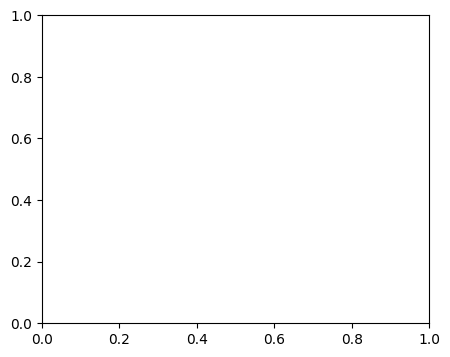

In [790]:
Generate_plot_over_under_studied(concept, DF_Hierarchies[concept],Country_codes,max_x=8,max_y=8,all_countries=True)

In [838]:
Filtered_DataFrame_out_filt[Filtered_DataFrame_out_filt.english_abstract.apply(lambda x: 'community initiative' in x.lower())]


,id,abstract,authorships.author.display_name,authorships.author.id,authorships.author.orcid,authorships.countries,authorships.is_corresponding,best_oa_location.license,cited_by_count,corresponding_institution_ids,...,Appearance_term_Continuum of violence,Probability_term_Pluriversal peace,Probability_string_term_Pluriversal peace,Appearance_term_Pluriversal peace,Probability_term_Decolonial peace,Probability_string_term_Decolonial peace,Appearance_term_Decolonial peace,Probability_term_Feminist Peace,Probability_string_term_Feminist Peace,Appearance_term_Feminist Peace
540,https://openalex.org/W1957119348,Este artículo revisa la literatura más represe...,Catherine González,https://openalex.org/A5108077231,NaN,CO,True,cc-by-nc-nd,23,https://openalex.org/I262776074,...,No,[0.45],>0.4,No,[0.46],>0.4,No,[0.48],>0.4,No
8089,https://openalex.org/W4406856574,"En los últimos años, se ha desarrollado una he...",Pablo Aragonés‐Beltrán,https://openalex.org/A5031169221,https://orcid.org/0000-0003-0538-9409,US,True,cc-by-nc-sa,0,https://openalex.org/I188538660|https://openal...,...,No,[0.25],<=0.4,No,[0.3],<=0.4,No,[0.31],<=0.4,No
14102,https://openalex.org/W4415178008,Abstract: Various tensions of ethnic conflict ...,Budi Agustono|Junaidi Junaidi|Kiki Maulana Aff...,https://openalex.org/A5037765980|https://opena...,https://orcid.org/0000-0003-0926-1787||https:/...,ID|ID|ID|ID|ID|KR,True|False|False|False|False|False,cc-by,0,https://openalex.org/I254887060,...,No,[0.41],>0.4,No,[0.43],>0.4,No,[0.35],<=0.4,No
15398,https://openalex.org/W7131226847,Os conflitos fundiários constituem uma temátic...,Íncare Correa de Jesus,https://openalex.org/A5045901517,https://orcid.org/0000-0002-1072-9028,NaN,True,NaN,0,NaN,...,No,[0.43],>0.4,No,[0.46],>0.4,No,[0.52],>0.5,No
35387,https://openalex.org/W3134174034,Ethnic and religious diversity have often been...,Yance Zadrak Rumahuru|Agustinus C. W. Gaspersz,https://openalex.org/A5051156755|https://opena...,https://orcid.org/0000-0003-4644-8524|,ID|ID,True|False,cc-by-sa,5,https://openalex.org/I4210148414|https://opena...,...,No,[0.45],>0.4,No,[0.43],>0.4,No,[0.4],<=0.4,No
35792,https://openalex.org/W2789241571,"In both Northern Ireland and Korea, the euphor...",Dong Jin Kim,https://openalex.org/A5014613587,https://orcid.org/0000-0002-8157-2769,IE,True,cc-by,5,https://openalex.org/I205274468,...,No,[0.39],<=0.4,No,[0.4],<=0.4,No,[0.38],<=0.4,No
45276,https://openalex.org/W1512236497,This paper reviews representative literature o...,Catherine González,https://openalex.org/A5108077231,NaN,CO,True,NaN,1,https://openalex.org/I262776074,...,No,[0.45],>0.4,No,[0.46],>0.4,No,[0.47],>0.4,No
46850,https://openalex.org/W4309066412,The signing of the peace agreement with the Re...,Rosaura Arrieta Flórez|Katleen Marún Uparela|S...,https://openalex.org/A5091475644|https://opena...,https://orcid.org/0000-0002-2026-6899|https://...,CO|CO|,True|False|False,cc-by-nc-nd,3,https://openalex.org/I153390918,...,No,[0.37],<=0.4,No,[0.44],>0.4,No,[0.39],<=0.4,No
57206,https://openalex.org/W4411745103,Thesis. The armed conflict in Colombia has had...,Luz Adriana Aristizábal Becerra|Adriana Inés Á...,https://openalex.org/A5084967997|https://opena...,https://orcid.org/0000-0002-3620-6276|https://...,CO|CO,True|False,cc-by,0,https://openalex.org/I192928004,...,No,[0.38],<=0.4,No,[0.46],>0.4,No,[0.48],>0.4,No
62963,https://openalex.org/W4413000022,Peace education globally equips students with ...,Nazri Ali|Diman Zuhair Sami Jacksi|Mohammed Sa...,https://openalex.org/A5068601902|https://opena...,https://orcid.org/0000-0001-9492-6645|||,IQ|IQ|IQ|IQ,True|False|False|False,cc-by,0,https://openalex.org/I36162470,...,No,[0.42],>0.4,No,[0.35],<=0.4,No,[0.45],>0.4,No


In [1002]:
concept = 'Intersectionality'
number = 0
Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+concept].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+concept]=='Yes')][['Appearance_term_'+concept]].iloc[number]


Appearance_term_Intersectionality    Yes
Name: 327, dtype: str

In [940]:
print(Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+concept].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+concept]=='Yes')][['english_abstract']].iloc[number])
Filtered_DataFrame_out_filt[(Filtered_DataFrame_out_filt['Probability_term_'+concept].apply(lambda x: x[0]>=prob_passing)) | (Filtered_DataFrame_out_filt['Appearance_term_'+concept]=='Yes')][['primary_topic.display_name']].iloc[number]

english_abstract    This is a reflection article result of the wor...
Name: 453, dtype: str


primary_topic.display_name    Criminal Justice and Penology
Name: 453, dtype: str